# Evaluating synthetic epidemic curves
Compare existing FPCA-generated curves with real outbreaks. This notebook measures feature fidelity, curve shape, coverage, diversity, and similarity to likely source curves. It does not train a forecaster.

**Run:** Put both CSVs beside the notebook (or in `upload/`), set the paths below if needed, and run all cells. Dependencies: `numpy pandas scipy matplotlib`. If you know which real curves were withheld from FPCA, set `HOLDOUT_IDS_CSV` to a CSV with a `unique_id` column. Otherwise the cohort comparison is descriptive, even after removing likely direct source rows.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import find_peaks
from scipy.spatial.distance import cdist, pdist
from scipy.stats import wasserstein_distance, ks_2samp
from IPython.display import display

REAL_CSV = Path('../raw_data/outbreaks_disease_location.csv')       # e.g. Path("outbreaks_disease_location.csv")
SYNTH_CSV = Path("../synthetic/output/synthetic_outbreaks_100.csv")
HOLDOUT_IDS_CSV = None
OUTPUT_DIR = Path("synthetic_evaluation")
N_REPEATS = 200
SEED = 42
GRID = np.linspace(0, 1, 64)
MIN_GROUP = 5  # skip smaller disease/event strata in stratified inference summaries
KEY = ["disease", "location", "event", "start_date", "end_date"]
GROUP = ["disease", "event"]
rng = np.random.default_rng(SEED)

def locate(explicit, names):
    if explicit is not None:
        return Path(explicit)
    for folder in (Path("."), Path("upload")):
        for name in names:
            if (folder / name).is_file():
                return folder / name
    raise FileNotFoundError(f"Set the input path for one of: {names}")

real_path = locate(REAL_CSV, ["outbreaks_disease_location.csv", "outbreak_disease_location.csv"])
syn_path = locate(SYNTH_CSV, ["synthetic_outbreaks_100.csv", "synthetic_outbreak_100.csv"])

## 1. Audit the files
Trim trailing padding. Exclude and report curves with internal gaps, nonnumeric entries, negative values, or fewer than four observations. Preserve observed zeros. Match likely source rows by metadata, never by row position.

In [2]:
def load_curves(path):
    df = pd.read_csv(path, dtype={"unique_id": str, "location": str})
    df.columns = df.columns.str.strip()
    missing = set(KEY + ["unique_id"]) - set(df)
    if missing:
        raise ValueError(f"{path}: missing columns {sorted(missing)}")
    weeks = sorted((c for c in df if c.isdigit()), key=int)
    if not weeks or list(map(int, weeks)) != list(range(len(weeks))):
        raise ValueError(f"{path}: expected consecutive numbered weekly columns starting at 0")
    for k in KEY:
        df[k] = df[k].astype("string").str.strip()
    for k in ("start_date", "end_date"):
        df[k] = pd.to_datetime(df[k], errors="coerce").dt.strftime("%Y-%m-%d")
    num = df[weeks].apply(pd.to_numeric, errors="coerce")
    bad_text = (df[weeks].notna() & num.isna()).any(axis=1)
    audit, curves = [], {}
    for i, y in enumerate(num.to_numpy(float)):
        ix = np.flatnonzero(~np.isnan(y))
        y = y[:ix[-1] + 1] if len(ix) else y[:0]
        flags = []
        if bad_text.iloc[i]: flags.append("nonnumeric")
        if len(y) < 4: flags.append("too_short")
        if np.isnan(y).any(): flags.append("internal_or_leading_gap")
        if np.isinf(y).any(): flags.append("infinite")
        if (y < 0).any(): flags.append("negative")
        if df.loc[i, GROUP].isna().any(): flags.append("missing_stratum")
        if not flags:
            curves[i] = y
        audit.append({"row": i, "unique_id": df.at[i, "unique_id"],
                      "status": "|".join(flags) or "valid", "window_weeks": len(y)})
    audit = pd.DataFrame(audit)
    audit["duplicate_id"] = df.unique_id.duplicated(keep=False)
    for field in ("total", "duration"):
        if field in df:
            audit[f"metadata_{field}"] = pd.to_numeric(df[field], errors="coerce")
    audit["curve_sum"] = pd.Series({i: y.sum() for i, y in curves.items()})
    if "metadata_total" in audit:
        audit["total_mismatch"] = (audit.metadata_total.notna() & audit.curve_sum.notna()
                                   & ~np.isclose(audit.metadata_total, audit.curve_sum))
    return df, curves, audit

real, ry, ra = load_curves(real_path)
syn, sy, sa = load_curves(syn_path)
audit = pd.concat([ra.assign(dataset="real"), sa.assign(dataset="synthetic")])
display(audit.groupby(["dataset", "status"]).size().rename("rows").to_frame())

rk = real[KEY].dropna().reset_index(names="real_row")
sk = syn[KEY].dropna().reset_index(names="synthetic_row")
matches = sk.merge(rk, on=KEY)
source_counts = matches.groupby("synthetic_row").size()
pairs = matches[matches.synthetic_row.map(source_counts).eq(1)].copy()
print(f"Unique metadata matches: {len(pairs)}; ambiguous: {(source_counts > 1).sum()}; "
      f"unmatched: {len(syn) - len(source_counts)}")

,,rows
dataset,status,
real,valid,9962
synthetic,valid,100


Unique metadata matches: 100; ambiguous: 0; unmatched: 0


## 2. Build outbreak features
Amplitude and burden are compared within disease/event strata. Autocorrelation and normalized roughness use the original weekly grid. Peak width below is the contiguous half-height span around the highest week; the peak count uses a prominence threshold of 10% of peak height. Flat or all-zero curves have undefined relative peak timing.

In [3]:
def describe(y):
    peak = y.max()
    p = int(np.argmax(y))
    flat = np.ptp(y) == 0
    z = y / peak if peak > 0 else np.zeros_like(y)
    width = np.nan
    if not flat:
        left = right = p
        while left > 0 and z[left - 1] >= 0.5: left -= 1
        while right + 1 < len(z) and z[right + 1] >= 0.5: right += 1
        width = right - left + 1
    a, b = y[:-1], y[1:]
    ac = np.corrcoef(a, b)[0, 1] if np.ptp(a) and np.ptp(b) else np.nan
    return dict(window_weeks=len(y), peak=peak, burden=y.sum(),
                peak_time=p / (len(y) - 1) if not flat else np.nan,
                width_weeks=width, width_relative=width / len(y),
                # Positive means more of the recorded window precedes the peak.
                asymmetry=2 * p / (len(y) - 1) - 1 if not flat else np.nan,
                prominent_peaks=len(find_peaks(z, prominence=0.10)[0]) if not flat else 0,
                zero_fraction=np.mean(y == 0), acf1=ac, roughness=np.mean(np.abs(np.diff(z))))

def make_features(df, curves):
    f = pd.DataFrame.from_dict({i: describe(y) for i, y in curves.items()}, orient="index")
    return df.loc[f.index, ["unique_id"] + KEY].join(f)

rf, sf = make_features(real, ry), make_features(syn, sy)
pool = rf.drop(index=matches.real_row.unique(), errors="ignore")
if HOLDOUT_IDS_CSV is not None:
    ids = pd.read_csv(HOLDOUT_IDS_CSV, dtype={"unique_id": str})["unique_id"]
    pool = pool[pool.unique_id.isin(ids)]
    if pool.empty:
        raise ValueError("No eligible real curves matched the holdout IDs.")
    print("Using user-supplied real holdout IDs; verify they were excluded from FPCA fitting.")
else:
    print("Descriptive fidelity: real generator-training membership is unknown.")
print(f"Eligible real reference curves: {len(pool):,}")

def normalized_shape(y):
    return np.interp(GRID, np.linspace(0, 1, len(y)), y / y.max() if y.max() else y)

rshape = {i: normalized_shape(y) for i, y in ry.items()}
sshape = {i: normalized_shape(y) for i, y in sy.items()}
grouper = GROUP
real_groups = dict(tuple(pool.groupby(grouper)))
syn_groups = dict(tuple(sf.groupby(grouper)))
counts = pd.concat([pool.groupby(GROUP).size().rename("eligible_real"),
                    sf.groupby(GROUP).size().rename("synthetic")], axis=1).fillna(0).astype(int)
display(counts)

Descriptive fidelity: real generator-training membership is unknown.
Eligible real reference curves: 9,862


eligible_real  synthetic
disease                       event                                       
CHICKENPOX [VARICELLA]        CASES                          25          0
COVID-19                      CASES                         914         13
                              HOSPITALIZATIONS              462          8
DIPHTHERIA                    CASES                         971         14
ILI                           PERCENT_UNWEIGHTED            783          7
INFLUENZA                     HOSPITALIZATIONS              329          2
MEASLES                       CASES                        1455         15
POLIOMYELITIS                 CASES                        2156         19
RSV                           HOSPITALIZATIONS               50          1
RUBELLA                       CASES                          81          0
SCARLET FEVER                 CASES                        1242          9
SMALLPOX                      CASES                        1112          9
TYPHOID FEVER [ENTERIC FEVER] CASES                          44          0
WHOOPING COUGH [PERTUSSIS]    CASES                         238          3

## 3. Compare feature distributions, shapes, and diversity
For each eligible disease/event stratum, repeatedly draw two disjoint real samples, each the size of the synthetic sample. Compare synthetic vs. real sample A and real sample B vs. real sample A. Use the same distances and sample sizes in both comparisons. Report medians and the central 95% range of the real-vs-real repeats. These ranges are descriptive references, not confidence intervals or p-values.

Wasserstein-1 retains feature units; KS ranges from 0 to 1. MMD² uses a fixed RBF bandwidth and feature scaling estimated from the eligible real reference pool. Its joint feature set excludes relative peak time and half-height width to retain flat curves. Joint MMD includes magnitude within each stratum; shape distances separately isolate morphology. Shape distances are RMS differences on peak-normalized curves. Larger directional nearest-neighbor distances indicate less coverage or less resemblance to the real reference, depending on direction. Compare within-set distances for diversity.

In [4]:
MARGINAL = ["peak", "burden", "window_weeks", "peak_time", "width_weeks",
            "width_relative", "asymmetry", "prominent_peaks", "zero_fraction", "acf1", "roughness"]
JOINT = ["peak", "burden", "window_weeks", "prominent_peaks", "zero_fraction", "roughness"]

def make_joint_transform(r, rng):
    x = r[JOINT].to_numpy(float)
    x[:, :2] = np.log1p(x[:, :2])  # temper heavy-tailed peak and burden
    center, scale = x.mean(axis=0), x.std(axis=0)
    scale = np.where(scale > 0, scale, 1.)
    def transform(df):
        a = df[JOINT].to_numpy(float)
        a[:, :2] = np.log1p(a[:, :2])
        return (a - center) / scale
    pilot = transform(r.iloc[rng.choice(len(r), min(400, len(r)), replace=False)])
    distances = pdist(pilot)
    positive = distances[distances > 0]
    bandwidth = float(np.median(positive)) if len(positive) else 1.
    return transform, bandwidth

def discrepancy(a, b, za, zb, xa, xb, bw):
    vals = {}
    for col in MARGINAL:
        x, y = a[col].dropna().to_numpy(), b[col].dropna().to_numpy()
        if len(x) >= 3 and len(y) >= 3:
            vals[f"W1:{col}"] = wasserstein_distance(x, y)
            vals[f"KS:{col}"] = ks_2samp(x, y, method="asymp").statistic
    def k(x, y):
        return np.exp(-cdist(x, y, "sqeuclidean") / (2 * bw**2)).mean()
    vals["MMD²"] = max(0., k(za, za) + k(zb, zb) - 2 * k(za, zb))
    d = cdist(xa, xb) / np.sqrt(xa.shape[1])
    vals["real_to_candidate_NN_RMS"] = np.median(d.min(axis=1))
    vals["candidate_to_real_NN_RMS"] = np.median(d.min(axis=0))
    vals["candidate_diversity_RMS"] = np.median(pdist(xb)) / np.sqrt(xb.shape[1])
    return vals, d

runs, neighbors, skipped = [], [], []
for group, s in syn_groups.items():
    r = real_groups.get(group, pool.iloc[:0])
    n = len(s)
    if n < MIN_GROUP or len(r) < 2 * n:
        skipped.append((*group, n, len(r), "Requires minimum synthetic count and two disjoint real samples"))
        continue
    transform, bandwidth = make_joint_transform(r, rng)
    sz = transform(s)
    sx = np.stack([sshape[i] for i in s.index])
    for rep in range(N_REPEATS):
        indices = rng.choice(len(r), 2 * n, replace=False)
        a, b = r.iloc[indices[:n]], r.iloc[indices[n:]]
        ax, bx = (np.stack([rshape[i] for i in df.index]) for df in (a, b))
        compared = [
            ("real_vs_synthetic", s, sz, sx),
            ("real_vs_real", b, transform(b), bx),
        ]
        for label, candidate, cz, cx in compared:
            values, dist = discrepancy(a, candidate, transform(a), cz, ax, cx, bandwidth)
            runs.extend((*group, rep, label, metric, value) for metric, value in values.items())
            if rep == 0:
                for direction, sample in [("coverage", dist.min(axis=1)), ("novelty", dist.min(axis=0))]:
                    neighbors.extend((*group, label, direction, v) for v in sample)

skipped = pd.DataFrame(skipped, columns=GROUP + ["synthetic_n", "eligible_real_n", "reason"])
runs = pd.DataFrame(runs, columns=GROUP + ["repeat", "comparison", "metric", "value"])
neighbors = pd.DataFrame(neighbors, columns=GROUP + ["comparison", "direction", "distance"])
summary = []
for index, g in runs.groupby(GROUP + ["metric"]):
    rs = g.loc[g.comparison.eq("real_vs_synthetic"), "value"]
    rr = g.loc[g.comparison.eq("real_vs_real"), "value"]
    if len(rs) and len(rr):
        summary.append((*index, rs.median(), rr.median(), rr.quantile(.025), rr.quantile(.975),
                        len(rs), len(rr)))
summary = pd.DataFrame(summary, columns=GROUP + ["metric", "real_synthetic_median",
                       "real_real_median", "real_real_q025", "real_real_q975",
                       "n_synthetic_comparisons", "n_real_comparisons"])
display(summary[summary.metric.isin(["MMD²", "W1:peak_time", "W1:roughness",
                                    "candidate_to_real_NN_RMS", "real_to_candidate_NN_RMS"])])
if not skipped.empty:
    display(skipped)

,disease,event,metric,real_synthetic_median,real_real_median,real_real_q025,real_real_q975,n_synthetic_comparisons,n_real_comparisons
11,COVID-19,CASES,MMD²,0.156422,0.053975,0.016788,0.128924,200,200
16,COVID-19,CASES,W1:peak_time,0.113712,0.071022,0.029538,0.150135,200,200
18,COVID-19,CASES,W1:roughness,0.016229,0.018525,0.007283,0.043111,200,200
24,COVID-19,CASES,candidate_to_real_NN_RMS,0.233030,0.180072,0.143370,0.229076,200,200
25,COVID-19,CASES,real_to_candidate_NN_RMS,0.209272,0.181487,0.138557,0.231615,200,200
37,COVID-19,HOSPITALIZATIONS,MMD²,0.202718,0.098465,0.031131,0.269375,200,200
42,COVID-19,HOSPITALIZATIONS,W1:peak_time,0.070585,0.077791,0.027764,0.182347,200,200
44,COVID-19,HOSPITALIZATIONS,W1:roughness,0.017926,0.020831,0.007370,0.073900,200,200
50,COVID-19,HOSPITALIZATIONS,candidate_to_real_NN_RMS,0.237352,0.170353,0.121941,0.214700,200,200
51,COVID-19,HOSPITALIZATIONS,real_to_candidate_NN_RMS,0.235671,0.172753,0.126591,0.235192,200,200


,disease,event,synthetic_n,eligible_real_n,reason
0,INFLUENZA,HOSPITALIZATIONS,2,329,Requires minimum synthetic count and two disjo...
1,RSV,HOSPITALIZATIONS,1,50,Requires minimum synthetic count and two disjo...
2,WHOOPING COUGH [PERTUSSIS],CASES,3,238,Requires minimum synthetic count and two disjo...


## 4. Inspect likely source pairs
A unique key match is a likely source, not proof of provenance. Small distances here can indicate inheritance or limited variation. Treat any feature deliberately preserved by the generator as a constraint.

In [5]:
pair_results = []
for p in pairs.itertuples(index=False):
    i, j = p.real_row, p.synthetic_row
    if i not in ry or j not in sy:
        continue
    same_length = len(ry[i]) == len(sy[j])
    pair_results.append(dict(real_row=i, synthetic_row=j, disease=p.disease, event=p.event,
        real_id=real.at[i, "unique_id"], synthetic_id=syn.at[j, "unique_id"],
        shape_rms=np.sqrt(np.mean((rshape[i] - sshape[j])**2)),
        exact_curve_match=same_length and np.array_equal(ry[i], sy[j]),
        length_change=sf.at[j, "window_weeks"] - rf.at[i, "window_weeks"],
        peak_time_change=sf.at[j, "peak_time"] - rf.at[i, "peak_time"],
        roughness_change=sf.at[j, "roughness"] - rf.at[i, "roughness"],
        burden_change=sf.at[j, "burden"] - rf.at[i, "burden"]))
pair_results = pd.DataFrame(pair_results)
if not pair_results.empty:
    display(pair_results.describe(include="number").round(3))
else:
    print("No valid uniquely matched pairs.")

,real_row,synthetic_row,shape_rms,length_change,peak_time_change,roughness_change,burden_change
count,100.000,100.000,100.000,100.0,100.000,100.000,100.0
mean,5072.890,49.500,0.318,0.0,0.020,-0.038,0.0
std,2833.922,29.011,0.090,0.0,0.271,0.076,0.0
min,27.000,0.000,0.131,0.0,-0.600,-0.411,-0.0
25%,3045.750,24.750,0.259,0.0,-0.160,-0.079,0.0
50%,5343.500,49.500,0.315,0.0,0.012,-0.023,0.0
75%,7207.000,74.250,0.380,0.0,0.144,0.011,0.0
max,9934.000,99.000,0.588,0.0,0.842,0.095,0.0


## 5. Plot and export
The figure shows one disease/event stratum. Set `PLOT_GROUP` to another tuple from the counts table. Nearest-neighbor plots use the first repeat, while the tables aggregate across repeats.

In [13]:
# PLOT_GROUP = None   # e.g. ("ILI", "PERCENT_UNWEIGHTED")

# if PLOT_GROUP is None and len(neighbors):
#     PLOT_GROUP = max(set(zip(neighbors.disease, neighbors.event)),
#                      key=lambda k: (len(syn_groups[k]), k))
# elif PLOT_GROUP is None and syn_groups:
#     PLOT_GROUP = max(syn_groups, key=lambda k: len(syn_groups[k]))

# OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
# if PLOT_GROUP is not None:
#     r = real_groups.get(PLOT_GROUP, pool.iloc[:0])
#     s = syn_groups[PLOT_GROUP]
#     prng = np.random.default_rng(SEED)
#     fig, axes = plt.subplots(1, 3, figsize=(15, 4), layout="constrained")
#     fig.suptitle(" / ".join(PLOT_GROUP))
#     for f, shapes, label, color in [(r, rshape, "Real", "#246590"),
#                                      (s, sshape, "Synthetic", "#d47a36")]:
#         if len(f) == 0:
#             continue
#         values = np.sort(f.peak_time.dropna())
#         if len(values):
#             axes[0].step(values, np.arange(1, len(values) + 1)/len(values),
#                          where="post", label=label, color=color)
#         selected = prng.choice(f.index, min(25, len(f)), replace=False)
#         for n, i in enumerate(selected):
#             axes[1].plot(GRID, shapes[i], alpha=.25, color=color, label=label if n == 0 else None)
#     axes[0].set(title="Relative peak timing", xlabel="Fraction of window", ylabel="Empirical CDF")
#     axes[1].set(title="Outbreak shapes", xlabel="Fraction of window", ylabel="Peak-normalized value")
#     nn = neighbors[(neighbors.disease == PLOT_GROUP[0]) & (neighbors.event == PLOT_GROUP[1])]
#     for (label, direction), g in nn.groupby(["comparison", "direction"]):
#         v = np.sort(g.distance)
#         axes[2].step(v, np.arange(1, len(v)+1)/len(v), where="post",
#                      label=f"{label.replace('_vs_', ' vs ')}: {direction}")
#     axes[2].set(title="Nearest-neighbor distances", xlabel="Curve RMS distance", ylabel="Empirical CDF")
#     if nn.empty:
#         axes[2].text(.5, .5, "Insufficient matched samples", ha="center", transform=axes[2].transAxes)
#     for ax in axes:
#         if ax.get_legend_handles_labels()[0]:
#             ax.legend(frameon=False, fontsize=8)
#     fig.savefig(OUTPUT_DIR / "comparison.png", dpi=150)
#     plt.show()

# for name, table in {
#     "audit": audit, "group_counts": counts.reset_index(), "skipped_groups": skipped,
#     "real_features": rf.reset_index(names="row"), "synthetic_features": sf.reset_index(names="row"),
#     "metric_summary": summary, "metric_repeats": runs, "nearest_neighbors": neighbors,
#     "metadata_matches": matches, "source_pair_metrics": pair_results,
# }.items():
#     table.to_csv(OUTPUT_DIR / f"{name}.csv", index=False)
# print(f"Saved tables to {OUTPUT_DIR.resolve()}")

## Real vs. Synthetic Outbreaks: Evaluation and Repeated Comparisons
- Evaluation: Compare outbreak magnitude, duration, peak timing/width, temporal variability, and zero-week frequency using joint-feature MMD²; assess normalized curve diversity and nearest-neighbor similarity.
  
- MMD^2 (group 1, group 2) = average similarity within group 1 + average similarity within within group 2 - 2 * average similarity between group 1 and group 2.
200 repeats. For each repeat \(r\), draw two disjoint real samples \(A_r\) and \(B_r\), each matching the size of the fixed synthetic set \(S\). Compute:

$d_{{RS},r} = MMD^2(A_r,S)
d_{{RR},r} = MMD^2(A_r,B_r).
$

  
- Stratification: Evaluate each disease × event group separately; require at least five synthetic curves. Fit MMD feature normalization once using the eligible real reference pool.
  
- 200 repeats: For a group with \(n\) synthetic curves, randomly draw two disjoint real samples of \(n\) curves each, without replacement within a repeat. Compare real A vs. synthetic and real A vs. real B; the synthetic sample stays fixed, while real samples change.

  
- Interpretation: Compare the median real–synthetic score across repeats with the central 95% range of real–real scores.

### Outbreak Features Used for Real–Synthetic Comparison
- Magnitude: Peak height, the maximum weekly value; total burden—the sum across the recorded window.
- Duration and peak timing: Number of observed weeks; peak position expressed as a fraction of the window.
- Peak width: Contiguous span around the highest peak with values at least 50% of peak height, measured in weeks and relative to window length.
- Peak position asymmetry: Relative amount of the recorded window before versus after the peak.
- Peak count: Number of interior local peaks with prominence of at least 10% of the maximum value.
- Temporal variability: Lag-1 autocorrelation measures week-to-week persistence; roughness measures the average absolute weekly change after peak normalization.
- Zero-week frequency: Fraction of observed weeks with exactly zero reported events; missing-value padding is excluded.

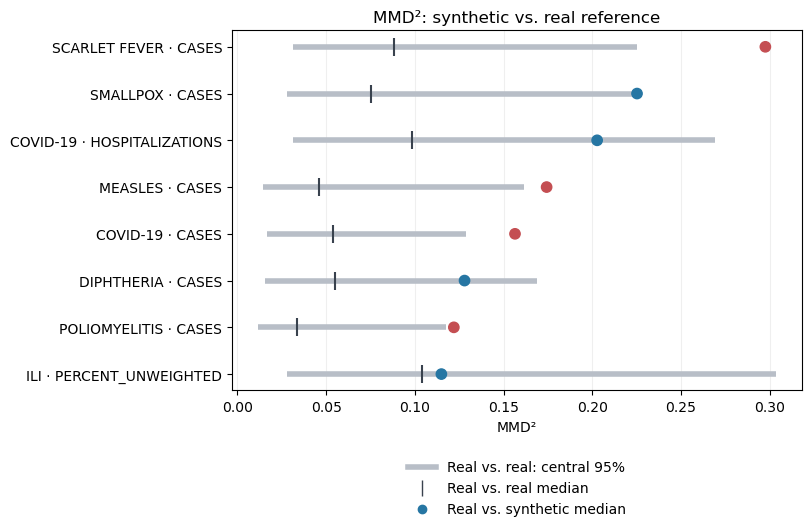

In [12]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D

scores = pd.read_csv("synthetic_evaluation/metric_summary.csv")

def plot_metric(metric, xlabel=None):
    d = (
        scores.loc[scores["metric"].eq(metric)]
        .sort_values("real_synthetic_median")
        .reset_index(drop=True)
    )
    if d.empty:
        raise ValueError(f"No rows found for {metric!r}")

    y = np.arange(len(d))
    x = d["real_synthetic_median"]
    lo, hi = d["real_real_q025"], d["real_real_q975"]
    colors = np.where(x > hi, "#C44E52",
             np.where(x < lo, "#8172B2", "#2676A3"))

    fig, ax = plt.subplots(figsize=(8, 0.45 * len(d) + 1.6),
                           layout="constrained")
    ax.hlines(y, lo, hi, color="#B8BEC7", linewidth=4)
    ax.scatter(d["real_real_median"], y, marker="|", s=160,
               color="#39424E", zorder=3)
    ax.scatter(x, y, c=colors, s=55, zorder=4)

    ax.set_yticks(y, d["disease"] + " · " + d["event"])
    ax.set(xlabel=xlabel or metric, title=f"{metric}: synthetic vs. real reference")
    ax.grid(axis="x", alpha=0.2)
    ax.legend(handles=[
        Line2D([0], [0], color="#B8BEC7", lw=4, label="Real vs. real: central 95%"),
        Line2D([0], [0], color="#39424E", marker="|", linestyle="none",
               markersize=12, label="Real vs. real median"),
        Line2D([0], [0], color="#2676A3", marker="o", linestyle="none",
               label="Real vs. synthetic median"),
    ], frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.16))
    return fig, ax

fig, ax = plot_metric("MMD²")
plt.show()

Of the 208 evaluated scores, 181 fell within the reference range, 26 fell above it, and 1 fell below it.
78 cells were not evaluated.


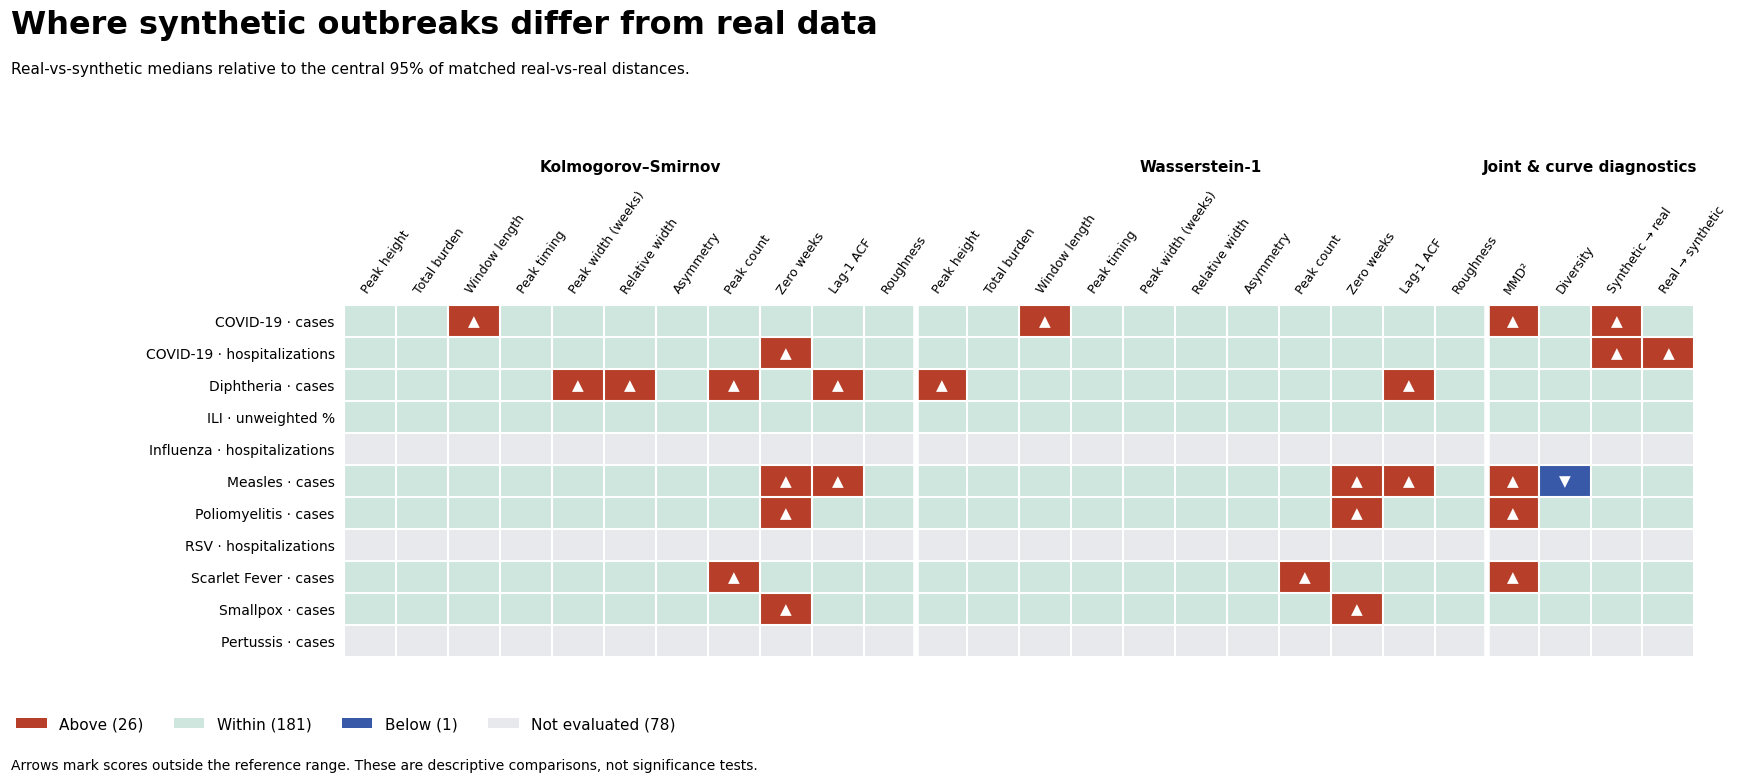

In [11]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch

SCORES_PATH = Path("synthetic_evaluation/metric_summary.csv")
SYNTHETIC_PATH = Path("../synthetic/output/synthetic_outbreaks_100.csv")
OUTPUT_PATH = Path("synthetic_outbreak_score_heatmap.png")

scores = pd.read_csv(SCORES_PATH)
synthetic = pd.read_csv(SYNTHETIC_PATH)

GROUP = ["disease", "event"]

FEATURE_LABELS = {
    "peak": "Peak height",
    "burden": "Total burden",
    "window_weeks": "Window length",
    "peak_time": "Peak timing",
    "width_weeks": "Peak width (weeks)",
    "width_relative": "Relative width",
    "asymmetry": "Asymmetry",
    "prominent_peaks": "Peak count",
    "zero_fraction": "Zero weeks",
    "acf1": "Lag-1 ACF",
    "roughness": "Roughness",
}

OTHER_LABELS = {
    "MMD²": "MMD²",
    "candidate_diversity_RMS": "Diversity",
    "candidate_to_real_NN_RMS": "Synthetic → real",
    "real_to_candidate_NN_RMS": "Real → synthetic",
}

METRICS = [
    f"{method}:{feature}"
    for method in ("KS", "W1")
    for feature in FEATURE_LABELS
] + list(OTHER_LABELS)

# Categories: 0 = not evaluated, 1 = below, 2 = within, 3 = above.
COLORS = ["#E8E9ED", "#3859A7", "#CEE6DE", "#B73F29"]


def classify_scores(df, rtol=1e-9, atol=1e-10):
    """Classify scores relative to the real-versus-real reference range."""
    result = df.copy()

    value = result["real_synthetic_median"].to_numpy(float)
    lower = result["real_real_q025"].to_numpy(float)
    upper = result["real_real_q975"].to_numpy(float)

    valid = np.isfinite(value) & np.isfinite(lower) & np.isfinite(upper)
    if np.any(valid & (lower > upper)):
        raise ValueError("Some reference ranges have lower > upper.")

    below = valid & (value < lower) & ~np.isclose(
        value, lower, rtol=rtol, atol=atol
    )
    above = valid & (value > upper) & ~np.isclose(
        value, upper, rtol=rtol, atol=atol
    )

    category = np.zeros(len(result), dtype=int)
    category[valid] = 2
    category[below] = 1
    category[above] = 3
    result["category"] = category

    return result


def plot_score_heatmap(scores, synthetic):
    if scores.duplicated(GROUP + ["metric"]).any():
        raise ValueError("Duplicate disease/event/metric rows found.")

    unknown = set(scores["metric"]) - set(METRICS)
    if unknown:
        raise ValueError(f"Unrecognized metrics: {sorted(unknown)}")

    classified = classify_scores(scores)

    # Include groups missing from the score CSV so they appear gray.
    groups = pd.MultiIndex.from_frame(
        pd.concat(
            [synthetic[GROUP], scores[GROUP]], ignore_index=True
        ).drop_duplicates()
    ).sort_values()

    matrix = (
        classified.pivot(
            index=GROUP, columns="metric", values="category"
        )
        .reindex(index=groups, columns=METRICS)
        .fillna(0)
        .astype(int)
    )

    counts = np.bincount(matrix.to_numpy().ravel(), minlength=4)

    event_labels = {
        "CASES": "cases",
        "HOSPITALIZATIONS": "hospitalizations",
        "PERCENT_UNWEIGHTED": "unweighted %",
    }

    def group_label(disease, event):
        disease_label = {
            "COVID-19": "COVID-19",
            "ILI": "ILI",
            "RSV": "RSV",
            "WHOOPING COUGH [PERTUSSIS]": "Pertussis",
        }.get(disease, disease.title())
        return f"{disease_label} · {event_labels.get(event, event)}"

    column_labels = [
        FEATURE_LABELS[m.split(":")[1]]
        if ":" in m else OTHER_LABELS[m]
        for m in METRICS
    ]

    fig, ax = plt.subplots(figsize=(18, 8), facecolor="white")
    fig.subplots_adjust(left=0.21, right=0.96, bottom=0.18, top=0.62)

    ax.imshow(
        matrix,
        aspect="auto",
        interpolation="none",
        cmap=ListedColormap(COLORS),
        norm=BoundaryNorm(np.arange(-0.5, 4.5), 4),
    )

    ax.xaxis.tick_top()
    ax.set_xticks(
        range(len(METRICS)),
        column_labels,
        rotation=55,
        ha="left",
        rotation_mode="anchor",
        fontsize=9,
    )
    ax.set_yticks(
        range(len(groups)),
        [group_label(*g) for g in groups],
        fontsize=10,
    )
    ax.tick_params(length=0, pad=7)

    # White cell borders and wider separators between metric families.
    for row in range(len(groups) + 1):
        ax.axhline(row - 0.5, color="white", linewidth=1.5)
    for col in range(len(METRICS) + 1):
        ax.axvline(
            col - 0.5,
            color="white",
            linewidth=4 if col in (11, 22) else 1.5,
        )

    values = matrix.to_numpy()
    for row, col in np.argwhere((values == 1) | (values == 3)):
        ax.text(
            col, row,
            "▼" if values[row, col] == 1 else "▲",
            ha="center", va="center",
            color="white", fontsize=11,
        )

    for spine in ax.spines.values():
        spine.set_visible(False)

    for left, right, label in [
        (0, 11, "Kolmogorov–Smirnov"),
        (11, 22, "Wasserstein-1"),
        (22, 26, "Joint & curve diagnostics"),
    ]:
        ax.text(
            (left + right) / (2 * len(METRICS)),
            1.38,
            label,
            transform=ax.transAxes,
            ha="center",
            fontsize=11,
            fontweight="bold",
        )

    fig.text(
        0.025, 0.96,
        "Where synthetic outbreaks differ from real data",
        fontsize=23, fontweight="bold",
    )
    fig.text(
        0.025, 0.91,
        "Real-vs-synthetic medians relative to the central 95% "
        "of matched real-vs-real distances.",
        fontsize=11,
    )

    legend_items = [
        (3, "Above"),
        (2, "Within"),
        (1, "Below"),
        (0, "Not evaluated"),
    ]
    fig.legend(
        handles=[
            Patch(facecolor=COLORS[code], label=f"{label} ({counts[code]})")
            for code, label in legend_items
        ],
        loc="lower left",
        bbox_to_anchor=(0.02, 0.07),
        ncol=4,
        frameon=False,
        fontsize=11,
    )
    fig.text(
        0.025, 0.04,
        "Arrows mark scores outside the reference range. "
        "These are descriptive comparisons, not significance tests.",
        fontsize=10,
    )

    print(
        f"Of the {counts[1:].sum()} evaluated scores, "
        f"{counts[2]} fell within the reference range, "
        f"{counts[3]} fell above it, and {counts[1]} fell below it."
    )
    print(f"{counts[0]} cells were not evaluated.")

    return fig, matrix, classified


fig, category_matrix, classified_scores = plot_score_heatmap(
    scores, synthetic
)

# fig.savefig(OUTPUT_PATH, dpi=200, bbox_inches="tight")
plt.show()